In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset Iris
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding label
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data 80:20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Dimensi X_train:', X_train.shape)
print('Dimensi y_train:', y_train.shape)


Dimensi X_train: (120, 4)
Dimensi y_train: (120, 3)


In [2]:
tf.random.set_seed(42)

# Model JST 2 hidden layer
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model 50 epoch
history_50 = model.fit(X_train, y_train, epochs=50, batch_size=5, validation_data=(X_test, y_test), verbose=0)

# Evaluasi hasil awal
loss_50, acc_50 = model.evaluate(X_test, y_test, verbose=0)
print(f'Konfigurasi Awal (50 Epoch, ReLU) - Loss: {loss_50:.4f}, Akurasi: {acc_50*100:.2f}%')


C:\Users\azure\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Konfigurasi Awal (50 Epoch, ReLU) - Loss: 0.2104, Akurasi: 100.00%


In [3]:
# Variasi jumlah neuron hidden layer (16 dan 8 neuron)
tf.random.set_seed(42)
model_neuron = tf.keras.Sequential([
    tf.keras.layers.Dense(16, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])
model_neuron.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_neuron = model_neuron.fit(X_train, y_train, epochs=50, batch_size=5, validation_data=(X_test, y_test), verbose=0)
loss_neuron, acc_neuron = model_neuron.evaluate(X_test, y_test, verbose=0)

# Variasi 100 Epoch
tf.random.set_seed(42)
model_100 = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])
model_100.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_100 = model_100.fit(X_train, y_train, epochs=100, batch_size=5, validation_data=(X_test, y_test), verbose=0)
loss_100, acc_100 = model_100.evaluate(X_test, y_test, verbose=0)

print(f'Variasi Neuron (16-8, 50 Epoch) - Loss: {loss_neuron:.4f}, Akurasi: {acc_neuron*100:.2f}%')
print(f'Variasi 100 Epoch (10-10, ReLU) - Loss: {loss_100:.4f}, Akurasi: {acc_100*100:.2f}%')


Variasi Neuron (16-8, 50 Epoch) - Loss: 0.1624, Akurasi: 96.67%
Variasi 100 Epoch (10-10, ReLU) - Loss: 0.1327, Akurasi: 96.67%


In [4]:
tf.random.set_seed(42)
# Model dengan fungsi aktivasi Sigmoid pada hidden layer
model_sigmoid = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='sigmoid', input_shape=(4,)),
    tf.keras.layers.Dense(10, activation='sigmoid'),
    tf.keras.layers.Dense(3, activation='softmax')
])
model_sigmoid.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_sig = model_sigmoid.fit(X_train, y_train, epochs=50, batch_size=5, validation_data=(X_test, y_test), verbose=0)
loss_sig, acc_sig = model_sigmoid.evaluate(X_test, y_test, verbose=0)

print(f'Aktivasi Sigmoid (50 Epoch) - Loss: {loss_sig:.4f}, Akurasi: {acc_sig*100:.2f}%')
print(f'Aktivasi ReLU    (50 Epoch) - Loss: {loss_50:.4f}, Akurasi: {acc_50*100:.2f}%')


Aktivasi Sigmoid (50 Epoch) - Loss: 0.5693, Akurasi: 96.67%
Aktivasi ReLU    (50 Epoch) - Loss: 0.2104, Akurasi: 100.00%


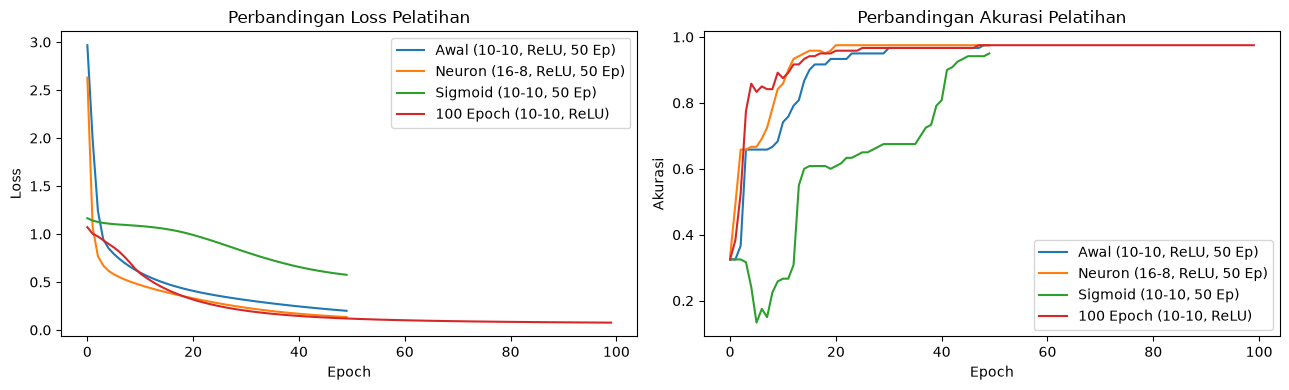

                       Konfigurasi  Loss Uji Akurasi Uji
0        Awal (10-10, ReLU, 50 Ep)  0.210431     100.00%
1      Tugas 2 (16-8, ReLU, 50 Ep)  0.162354      96.67%
2    Tugas 2 (10-10, ReLU, 100 Ep)  0.132742      96.67%
3  Tugas 3 (10-10, Sigmoid, 50 Ep)  0.569324      96.67%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_50.history['loss'], label='Awal (10-10, ReLU, 50 Ep)')
axes[0].plot(history_neuron.history['loss'], label='Neuron (16-8, ReLU, 50 Ep)')
axes[0].plot(history_sig.history['loss'], label='Sigmoid (10-10, 50 Ep)')
axes[0].plot(history_100.history['loss'], label='100 Epoch (10-10, ReLU)')
axes[0].set_title('Perbandingan Loss Pelatihan')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history_50.history['accuracy'], label='Awal (10-10, ReLU, 50 Ep)')
axes[1].plot(history_neuron.history['accuracy'], label='Neuron (16-8, ReLU, 50 Ep)')
axes[1].plot(history_sig.history['accuracy'], label='Sigmoid (10-10, 50 Ep)')
axes[1].plot(history_100.history['accuracy'], label='100 Epoch (10-10, ReLU)')
axes[1].set_title('Perbandingan Akurasi Pelatihan')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Akurasi')
axes[1].legend()

plt.tight_layout()
plt.show()

df_komparasi = pd.DataFrame({
    'Konfigurasi': ['Awal (10-10, ReLU, 50 Ep)', 'Tugas 2 (16-8, ReLU, 50 Ep)', 'Tugas 2 (10-10, ReLU, 100 Ep)', 'Tugas 3 (10-10, Sigmoid, 50 Ep)'],
    'Loss Uji': [loss_50, loss_neuron, loss_100, loss_sig],
    'Akurasi Uji': [f'{acc_50*100:.2f}%', f'{acc_neuron*100:.2f}%', f'{acc_100*100:.2f}%', f'{acc_sig*100:.2f}%']
})
print(df_komparasi)
